# Notebook 4 — LoRA fine-tuning of Llama 3 8B on SciEntsBank  ·  GPU: T4

Fine-tunes on the official SemEval-2013 training answers (minus the question-grouped validation set), picks the checkpoint with the lowest validation NLL, and classifies the three official test sets (unseen answers / questions / domains).

- Same prompt as the zero-shot run; target = label word (`correct`, `partial`, `contradictory`, `irrelevant`, `non-domain`) + EOS; loss only on the target tokens.
- Identical hyper-parameters to the Mohler runs (LoRA r=16, α=16, all projections; 2 epochs; lr 2e-4; batch 8; fp16; seed 42).
- Prediction from the next-token probabilities of the five labels, as in Notebook 2. Reported: **raw** (argmax), plus **calibrated** (logistic regression fitted on the validation predictions only).

**Timing:** training ≈ 90–100 min and must finish in one go, so **start this notebook in a fresh session**. The LoRA weights are saved when training ends; the test scoring after that (~15–20 min) is resumable.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys
ROOT = '/content/drive/MyDrive/asag_revision'
sys.path.insert(0, ROOT)
os.makedirs(f'{ROOT}/models', exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
!pip -q install -U bitsandbytes accelerate peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 64.2 MB/s eta 0:00:00


In [3]:
import json, gc, time, platform
import numpy as np, pandas as pd, torch, transformers, bitsandbytes, peft
from tqdm.auto import tqdm
from asag_utils import *
from llm_utils import *

versions = {'python': platform.python_version(), 'torch': torch.__version__, 'transformers': transformers.__version__,
            'bitsandbytes': bitsandbytes.__version__, 'peft': peft.__version__, 'gpu': torch.cuda.get_device_name(0)}
se = pd.read_csv(f'{ROOT}/data/scientsbank_prepared.csv')
prompts = make_prompts(se, 'scientsbank')
ADAPTER = f'{ROOT}/models/scientsbank_llama3_ft'
LOG = f'{ROOT}/results/nb4_trainlog.json'
OUT = f'{ROOT}/results/scientsbank_llama3_ft.csv'
lp_cols = [f'lp_{l}' for l in LABEL_ORDER]
se.split.value_counts()

,count
split,
test_ud,4562
train,4472
test_uq,733
test_ua,540
val,497


## 1. Train (skipped if the adapter from a previous session exists)

In [4]:
model = None
if os.path.exists(LOG) and os.path.exists(f'{ADAPTER}/adapter_config.json'):
    print('Adapter already trained:', ADAPTER)
else:
    t0 = time.time()
    model, tok = load_hf_4bit(BASE_MODEL)
    cand, _ = candidate_ids(tok, label_candidates(chat=False))
    model, n_trainable = add_lora(model, seed=SEED)
    tr, va = se[se.split == 'train'], se[se.split == 'val']
    ex = build_examples(tok, [prompts[i] for i in tr.index], [LABEL_WORDS[l] for l in tr.label])
    first = {l: c for l, c in zip(LABEL_ORDER, cand)}
    assert all(t[0] == first[l] and t[-1] == tok.eos_token_id for (_, t), l in zip(ex, tr.label)), 'target tokenisation mismatch'
    print(f'train {len(tr)}  val {len(va)}  trainable params {n_trainable:,}  max length {max(len(p) + len(t) for p, t in ex)} tokens')

    val_texts = [prompts[i] for i in va.index]
    vy = np.array([LABEL_ORDER.index(l) for l in va.label])
    def evaluate():
        lp = candidate_logprobs(model, tok, val_texts, cand, batch_size=8)
        _, mass, pr = labels_from_logprobs(lp)
        return {'val_nll': float(-lp[np.arange(len(vy)), vy].mean()),       # first label token, as scored at inference
                'val_macro_f1': cls_metrics(va.label.values, pr['5way'])['macro_f1'],
                'val_acc': cls_metrics(va.label.values, pr['5way'])['acc'], 'val_mass': float(mass.mean())}

    torch.cuda.reset_peak_memory_stats()
    hist, best = train_lora(model, tok, ex, evaluate, seed=SEED)
    model.save_pretrained(ADAPTER)
    hist.update(n_train=len(tr), n_val=len(va), trainable_params=n_trainable, best=best,
                peak_vram_gb=torch.cuda.max_memory_allocated() / 1e9, train_minutes=(time.time() - t0) / 60)
    json.dump(hist, open(LOG, 'w'), indent=1, default=float)     # written last: marks training as finished
    print(f'training done in {hist["train_minutes"]:.1f} min; best checkpoint at epoch {best["epoch"]:.1f}; '
          f'val macro-F1 {best["val_macro_f1"]:.3f}')

config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.6k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.70GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/198 [00:00<?, ?B/s]

224 4-bit layers; compute dtype before: ['torch.bfloat16'] -> torch.float16
train 4472  val 497  trainable params 41,943,040  max length 458 tokens
step 50/1118  loss 0.5865  4.85s/step
step 100/1118  loss 0.4340  5.16s/step
step 150/1118  loss 0.4103  5.32s/step
step 200/1118  loss 0.4174  5.38s/step
step 250/1118  loss 0.2950  5.53s/step
eval {'step': 280, 'epoch': 0.5008944543828264, 'val_nll': 0.9182508587837219, 'val_macro_f1': np.float64(0.4699511319437518), 'val_acc': np.float64(0.6639839034205232), 'val_mass': 0.9925751090049744}
step 300/1118  loss 0.5989  6.03s/step
step 350/1118  loss 0.2572  5.94s/step
step 400/1118  loss 0.3011  5.89s/step
step 450/1118  loss 0.3795  5.87s/step
step 500/1118  loss 0.2969  5.84s/step
step 550/1118  loss 0.2430  5.86s/step
eval {'step': 559, 'epoch': 1.0, 'val_nll': 0.9192498922348022, 'val_macro_f1': np.float64(0.556676305447058), 'val_acc': np.float64(0.6861167002012073), 'val_mass': 0.9964194297790527}
step 600/1118  loss 0.1430  6.09s/st

## 2. Score validation + the three test sets (resumable, saves every 256 answers)

In [5]:
if model is None:
    model, tok = load_hf_4bit(BASE_MODEL, adapter=ADAPTER)
    cand, _ = candidate_ids(tok, label_candidates(chat=False))
PRIORITY = ['test_ua', 'test_uq', 'test_ud', 'val']
done_ids = set(pd.read_csv(OUT).uid) if os.path.exists(OUT) else set()
rows = se[se.split.isin(PRIORITY)]
rows = rows.assign(pr=rows.split.map(PRIORITY.index)).sort_values('pr', kind='stable')
todo = [i for i in rows.index if se.uid[i] not in done_ids]
t0 = time.time()
for start in tqdm(range(0, len(todo), 256)):
    idx = todo[start:start + 256]
    lp = candidate_logprobs(model, tok, [prompts[i] for i in idx], cand, batch_size=8)
    chunk = pd.concat([pd.DataFrame({'uid': se.uid.values[idx]}), pd.DataFrame(lp, columns=lp_cols)], axis=1)
    chunk.to_csv(OUT, mode='a', header=not os.path.exists(OUT), index=False)
if todo:
    print(f'{1000 * (time.time() - t0) / len(todo):.0f} ms per answer')
del model; gc.collect(); torch.cuda.empty_cache()

  0%|          | 0/25 [00:00<?, ?it/s]

239 ms per answer


## 3. Results

In [6]:
from sklearn.linear_model import LogisticRegression
label_col = {'5way': 'label', '3way': 'label3', '2way': 'label2'}
z = pd.read_csv(OUT).drop_duplicates('uid')
d = se[['uid', 'split'] + list(label_col.values())].merge(z, on='uid')
assert len(d) == se.split.isin(PRIORITY).sum(), 'scoring incomplete: re-run section 2'
q, mass, raw = labels_from_logprobs(d[lp_cols].values)
feats = np.log(np.clip(q, 1e-12, 1))
fit = (d.split == 'val').values                       # calibration fitted on validation predictions only
new = pd.DataFrame({'uid': d.uid})
for scheme, col in label_col.items():
    new[f'llama3_ft_{scheme}'] = raw[scheme]
    clf = LogisticRegression(max_iter=2000).fit(feats[fit], d[col].values[fit])
    new[f'llama3_ft_cal_{scheme}'] = clf.predict(feats)
preds = pd.read_csv(f'{ROOT}/results/scientsbank_preds.csv')
preds = preds.drop(columns=[c for c in new.columns if c != 'uid' and c in preds.columns]).merge(new, on='uid', how='left')
preds.to_csv(f'{ROOT}/results/scientsbank_preds.csv', index=False)
print(f'mean valid mass {mass.mean():.3f}')

TESTS = ['test_ua', 'test_uq', 'test_ud']
rows = []
for scheme, col in label_col.items():
    for name in ['llama3_ft', 'llama3_ft_cal']:
        for t in TESTS:
            dd = preds[preds.split == t]
            rows.append({'scheme': scheme, 'system': name, 'test': t, 'n': len(dd),
                         **summarise(dd[col], dd[f'{name}_{scheme}'], cls_metrics,
                                     groups=None if t == 'test_ua' else dd.group)})
nb4 = pd.DataFrame(rows); nb4.to_csv(f'{ROOT}/results/scientsbank_nb4_summary.csv', index=False)
ref = pd.concat([pd.read_csv(f'{ROOT}/results/scientsbank_nb0_summary.csv'),
                 pd.read_csv(f'{ROOT}/results/scientsbank_nb2_summary.csv')])
both = pd.concat([ref[ref.system.isin(['majority', 'lexical_4', 'llama3_base_zs_cal', 'llama3_instruct_zs_cal'])], nb4])
for metric in ['macro_f1', 'acc']:
    print(metric); display(both.pivot_table(index=['scheme', 'system'], columns='test', values=metric)[TESTS].round(3))
display(nb4[['scheme', 'system', 'test', 'macro_f1', 'macro_f1_ci', 'acc', 'acc_ci']].round(3))

mean valid mass 0.998
macro_f1


test                           test_ua  test_uq  test_ud
scheme system                                           
2way   lexical_4                 0.666    0.685    0.690
       llama3_base_zs_cal        0.716    0.693    0.698
       llama3_ft                 0.830    0.820    0.769
       llama3_ft_cal             0.847    0.825    0.767
       llama3_instruct_zs_cal    0.747    0.806    0.712
       majority                  0.362    0.371    0.367
3way   lexical_4                 0.417    0.450    0.442
       llama3_base_zs_cal        0.559    0.541    0.529
       llama3_ft                 0.775    0.746    0.733
       llama3_ft_cal             0.792    0.742    0.733
       llama3_instruct_zs_cal    0.622    0.652    0.567
       majority                  0.210    0.223    0.219
5way   lexical_4                 0.253    0.294    0.265
       llama3_base_zs_cal        0.354    0.414    0.366
       llama3_ft                 0.581    0.522    0.720
       llama3_ft_cal             0.689    0.526    0.698
       llama3_instruct_zs_cal    0.523    0.418    0.572
       majority                  0.121    0.146    0.118

acc


test                           test_ua  test_uq  test_ud
scheme system                                           
2way   lexical_4                 0.693    0.697    0.702
       llama3_base_zs_cal        0.730    0.716    0.707
       llama3_ft                 0.835    0.829    0.776
       llama3_ft_cal             0.850    0.831    0.770
       llama3_instruct_zs_cal    0.754    0.814    0.715
       majority                  0.569    0.589    0.580
3way   lexical_4                 0.596    0.645    0.633
       llama3_base_zs_cal        0.652    0.651    0.639
       llama3_ft                 0.789    0.782    0.737
       llama3_ft_cal             0.806    0.775    0.732
       llama3_instruct_zs_cal    0.685    0.748    0.644
       majority                  0.461    0.502    0.488
5way   lexical_4                 0.507    0.497    0.513
       llama3_base_zs_cal        0.554    0.539    0.540
       llama3_ft                 0.733    0.670    0.661
       llama3_ft_cal             0.757    0.675    0.664
       llama3_instruct_zs_cal    0.602    0.603    0.565
       majority                  0.431    0.411    0.420

,scheme,system,test,macro_f1,macro_f1_ci,acc,acc_ci
0,5way,llama3_ft,test_ua,0.581,"[0.548, 0.728]",0.733,"[0.696, 0.772]"
1,5way,llama3_ft,test_uq,0.522,"[0.461, 0.707]",0.670,"[0.587, 0.753]"
2,5way,llama3_ft,test_ud,0.720,"[0.670, 0.755]",0.661,"[0.599, 0.710]"
3,5way,llama3_ft_cal,test_ua,0.689,"[0.566, 0.800]",0.757,"[0.719, 0.793]"
4,5way,llama3_ft_cal,test_uq,0.526,"[0.473, 0.704]",0.675,"[0.592, 0.757]"
5,5way,llama3_ft_cal,test_ud,0.698,"[0.652, 0.733]",0.664,"[0.614, 0.713]"
6,3way,llama3_ft,test_ua,0.775,"[0.732, 0.815]",0.789,"[0.756, 0.822]"
7,3way,llama3_ft,test_uq,0.746,"[0.638, 0.828]",0.782,"[0.717, 0.842]"
8,3way,llama3_ft,test_ud,0.733,"[0.664, 0.784]",0.737,"[0.674, 0.789]"
9,3way,llama3_ft_cal,test_ua,0.792,"[0.747, 0.831]",0.806,"[0.770, 0.839]"


## 4. Error analysis: per-class F1 and confusion matrices (5-way, fine-tuned raw)

In [7]:
from sklearn.metrics import confusion_matrix, f1_score
per_class = []
for t in TESTS:
    dd = preds[preds.split == t]
    f1 = f1_score(dd.label, dd.llama3_ft_5way, labels=LABEL_ORDER, average=None, zero_division=0)
    per_class.append({'test': t, **dict(zip(LABEL_ORDER, f1))})
    cm = pd.DataFrame(confusion_matrix(dd.label, dd.llama3_ft_5way, labels=LABEL_ORDER),
                      index=[f'gold {l}' for l in LABEL_ORDER], columns=[f'pred {l[:7]}' for l in LABEL_ORDER])
    cm.to_csv(f'{ROOT}/results/scientsbank_confusion_{t}.csv')
    print(t); display(cm)
per_class = pd.DataFrame(per_class); per_class.to_csv(f'{ROOT}/results/scientsbank_perclass_f1.csv', index=False)
display(per_class.round(3))

test_ua


,pred correct,pred partial,pred contrad,pred irrelev,pred non_dom
gold correct,178,50,2,3,0
gold partially_correct_incomplete,26,73,3,11,0
gold contradictory,1,7,42,8,0
gold irrelevant,7,16,7,103,0
gold non_domain,0,1,0,2,0


test_uq


,pred correct,pred partial,pred contrad,pred irrelev,pred non_dom
gold correct,229,61,3,8,0
gold partially_correct_incomplete,35,103,3,34,0
gold contradictory,5,10,39,10,0
gold irrelevant,14,46,12,120,1
gold non_domain,0,0,0,0,0


test_ud


,pred correct,pred partial,pred contrad,pred irrelev,pred non_dom
gold correct,1409,429,25,54,0
gold partially_correct_incomplete,357,537,31,61,0
gold contradictory,29,42,315,31,0
gold irrelevant,138,260,90,733,1
gold non_domain,0,0,0,0,20


,test,correct,partially_correct_incomplete,contradictory,irrelevant,non_domain
0,test_ua,0.800,0.562,0.750,0.792,0.000
1,test_uq,0.784,0.522,0.645,0.658,0.000
2,test_ud,0.732,0.476,0.718,0.698,0.976


{'n_train': 4472, 'n_val': 497, 'total_steps': 1118, 'sec_per_step': 6.091756363034461, 'train_minutes': 114.87403107881546, 'peak_vram_gb': 8.192966144, 'trainable_params': 41943040, 'best_epoch': 2.0}


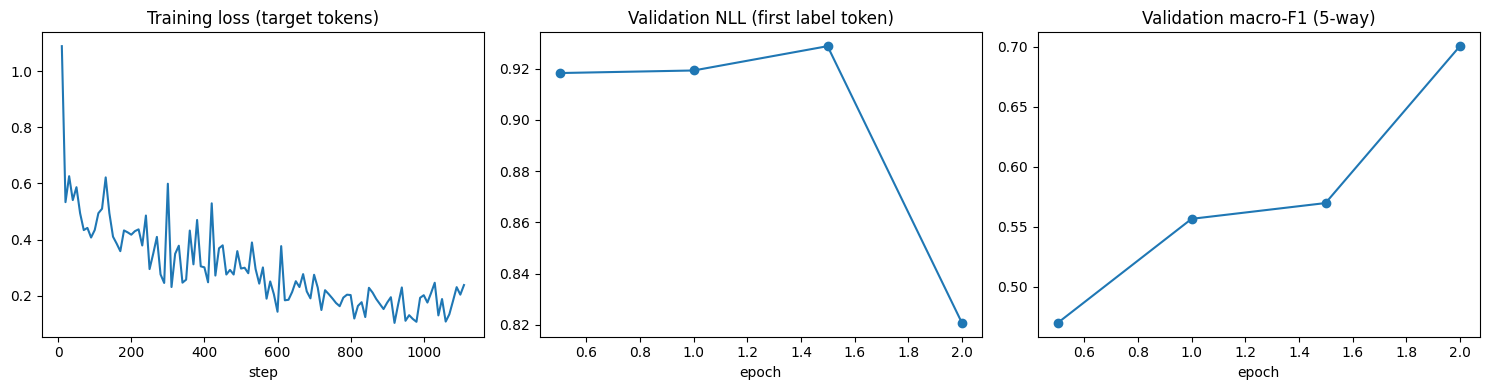

In [8]:
import matplotlib.pyplot as plt
h = json.load(open(LOG))
cost = {k: h[k] for k in ['n_train', 'n_val', 'total_steps', 'sec_per_step', 'train_minutes', 'peak_vram_gb', 'trainable_params']}
cost['best_epoch'] = h['best']['epoch']; print(cost)
json.dump(cost, open(f'{ROOT}/results/nb4_training_cost.json', 'w'), indent=1, default=float)
tr, ev = pd.DataFrame(h['train']), pd.DataFrame(h['eval'])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(tr.step, tr.loss); ax[0].set_title('Training loss (target tokens)'); ax[0].set_xlabel('step')
ax[1].plot(ev.epoch, ev.val_nll, 'o-'); ax[1].set_title('Validation NLL (first label token)'); ax[1].set_xlabel('epoch')
ax[2].plot(ev.epoch, ev.val_macro_f1, 'o-'); ax[2].set_title('Validation macro-F1 (5-way)'); ax[2].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(f'{ROOT}/results/fig_scientsbank_learning_curves.png', dpi=300); plt.show()
json.dump(versions, open(f'{ROOT}/results/env_nb4.json', 'w'), indent=2)